# Location-Based Analysis

## Objective

Conduct a geographical analysis of the company's `Dataset.csv`, containing 9551 restaurants and 21 columns. The analysis covers restaurant coordinates and maps, city and locality concentration, location-wise statistics, and key insights.

## How to run

Upload `Dataset.csv` to Google Colab, then select Runtime → Run all. No additional files are required. The notebook automatically generates `restaurant_map.html`.

## Notebook structure

1. Coordinate exploration
2. Map visualisation
3. Concentration analysis
4. City statistics
5. Locality specialties
6. Insights and patterns
7. Charts and city profile function

## Key caveats

* 497 restaurants have both coordinates set to zero, and 500 records are flagged as invalid overall (499 with a zero coordinate, plus one test entry).
* Cities outside Delhi NCR appear to contain samples of approximately 20 restaurants, so their restaurant counts should not be interpreted as actual geographical densities.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
from collections import Counter

df = pd.read_csv("Dataset.csv")
print("Shape (rows, columns):", df.shape)

# Repair the three corrupted city names found in Task 1
def fix_city(name):
    if name.isascii():
        return name
    if name.endswith('stanbul'):
        return 'Istanbul'
    if name.startswith('S') and name.endswith('o Paulo'):
        return 'Sao Paulo'
    if name.startswith('Bras') and name.endswith('lia'):
        return 'Brasilia'
    return name

df['City'] = df['City'].apply(fix_city)
print("Non-ASCII cities left:", [c for c in df['City'].unique() if not c.isascii()])
print("Unique cities:", df['City'].nunique())
print()

# First look at the coordinates
print(df[['Latitude', 'Longitude']].describe().round(3))
print()
print("Rows with latitude 0 and longitude 0:", ((df['Latitude'] == 0) & (df['Longitude'] == 0)).sum())
print("Rows with latitude 0 or longitude 0 (either):", ((df['Latitude'] == 0) | (df['Longitude'] == 0)).sum())
print("Missing coordinates:", df[['Latitude', 'Longitude']].isnull().sum().sum())

Shape (rows, columns): (9551, 21)
Non-ASCII cities left: []
Unique cities: 141

       Latitude  Longitude
count  9551.000   9551.000
mean     25.854     64.127
std      11.008     41.467
min     -41.330   -157.948
25%      28.479     77.081
50%      28.570     77.192
75%      28.643     77.282
max      55.977    174.832

Rows with latitude 0 and longitude 0: 497
Rows with latitude 0 or longitude 0 (either): 499
Missing coordinates: 0


In [2]:
zero = (df['Latitude'] == 0) & (df['Longitude'] == 0)
print("Zero-coordinate rows by country code:")
print(df[zero]['Country Code'].value_counts())
print()
print("Top cities among zero-coordinate rows:")
print(df[zero]['City'].value_counts().head(10))
print()

# The 2 rows with only one coordinate at 0
one = ((df['Latitude'] == 0) | (df['Longitude'] == 0)) & ~zero
print("Rows with exactly one zero coordinate:")
print(df[one][['Restaurant Name', 'City', 'Latitude', 'Longitude']])
print()

# For rows with real coordinates: how far is each from its city's median position?
ok = df[~zero & ~one].copy()
med = ok.groupby('City')[['Latitude', 'Longitude']].median()
ok = ok.join(med, on='City', rsuffix='_med')
# rough distance in km (1 degree of latitude is about 111 km; scale longitude by cos(lat))
dlat = (ok['Latitude'] - ok['Latitude_med']) * 111
dlon = (ok['Longitude'] - ok['Longitude_med']) * 111 * np.cos(np.radians(ok['Latitude_med']))
ok['km_from_city_median'] = np.sqrt(dlat**2 + dlon**2)
print("Distance from the city median (km), all valid rows:")
print(ok['km_from_city_median'].describe().round(1))
print("Rows more than 50 km from their city's median:", (ok['km_from_city_median'] > 50).sum())
print()
print(ok[ok['km_from_city_median'] > 50][['Restaurant Name', 'City', 'Latitude', 'Longitude',
      'km_from_city_median']].sort_values('km_from_city_median', ascending=False).head(10).round(2))

Zero-coordinate rows by country code:
Country Code
1      495
94       1
191      1
Name: count, dtype: int64

Top cities among zero-coordinate rows:
City
New Delhi    233
Noida         93
Gurgaon       48
Faridabad     22
Vadodara      10
Mangalore      9
Varanasi       7
Dehradun       7
Guwahati       6
Agra           6
Name: count, dtype: int64

Rows with exactly one zero coordinate:
     Restaurant Name      City  Latitude   Longitude
8620       InnerChef     Noida      28.0    0.000000
9312  Winona Forever  Auckland       0.0  174.779441

Distance from the city median (km), all valid rows:
count    9052.0
mean        7.3
std        45.2
min         0.0
25%         2.9
50%         6.5
75%         9.5
max      4268.6
Name: km_from_city_median, dtype: float64
Rows more than 50 km from their city's median: 12

                 Restaurant Name            City  Latitude  Longitude  \
3513  Test Restaruants for Medio       New Delhi     35.00      34.00   
417         Kona Brewing Compa

In [3]:
# Validity flag: zero or single-zero coordinates, plus the one test row far from its city
bad_zero = (df['Latitude'] == 0) | (df['Longitude'] == 0)
bad_test = df['Restaurant Name'].str.contains('Test Restaruants', case=False, na=False) & \
           (df['City'] == 'New Delhi') & (df['Latitude'] == 35.0)
df['coord_valid'] = ~(bad_zero | bad_test)

print("Valid coordinates:", df['coord_valid'].sum(), "| invalid:", (~df['coord_valid']).sum())
print("Invalid by cause: zeros", int(bad_zero.sum()), "| test row", int(bad_test.sum()))
print()

# Share invalid per city (cities with 100+ restaurants)
g = df.groupby('City')['coord_valid'].agg(total='size', invalid=lambda s: (~s).sum())
g['invalid_share'] = (g['invalid'] / g['total']).round(3)
print(g[g['total'] >= 100].sort_values('invalid_share', ascending=False))
print()

# Valid coordinate ranges by country code (sanity check)
v = df[df['coord_valid']]
print(v.groupby('Country Code')[['Latitude', 'Longitude']].agg(['min', 'max']).round(1))

Valid coordinates: 9051 | invalid: 500
Invalid by cause: zeros 499 | test row 1

           total  invalid  invalid_share
City                                    
Faridabad    251       22          0.088
Noida       1080       94          0.087
Gurgaon     1118       48          0.043
New Delhi   5473      234          0.043

             Latitude       Longitude       
                  min   max       min    max
Country Code                                
1                10.0  31.7      72.5   91.8
14              -38.6 -16.7     116.0  153.6
30              -23.6 -15.7     -48.0  -43.2
37               42.4  52.0    -110.8  -79.4
94               -6.9  -6.1     106.7  107.6
148             -41.3 -36.8     174.6  174.8
162              14.1  14.6     121.0  121.1
166              25.2  25.4      51.4   51.5
184               1.3   1.3     103.8  103.9
189             -34.0 -25.8      18.4   28.3
191               6.9   6.9      79.8   79.9
208              39.9  41.1      29.0   32

## Coordinate Exploration Summary

* The dataset contains 9551 restaurants across 141 cities, after correcting 3 corrupted city names: Istanbul, Sao Paulo, and Brasilia.
* A total of 499 restaurants have a zero latitude or longitude, including 497 with both coordinates set to zero. These represent missing location data rather than actual coordinates. One additional test entry in New Delhi, with coordinates 35.0, 34.0, is approximately 4268 km from the city. Overall, 500 rows are flagged as `coord_valid = False`, leaving 9051 usable map points.
* Of the invalid rows, 495 out of 497 double-zero entries are in India. Most are concentrated in New Delhi (234 flagged), Noida (94), Gurgaon (48), and Faridabad (22). The invalid coordinate shares are 8.8% in Faridabad, 8.7% in Noida, and 4.3% in both Gurgaon and New Delhi.
* For valid coordinates, the median distance from the city's median position is 6.5 km. Only 12 of 9052 checked rows are more than 50 km away from their city's median position. One of these is the Medio test entry, and the other 11 are in Rest of Hawaii, an island group where such distances are expected.
* Invalid coordinate rows are excluded only from mapping and distance-based analyses. They remain included in ratings, cuisine, and price statistics because those values are still valid.
* The valid coordinate ranges for each country code fall within plausible geographic regions.

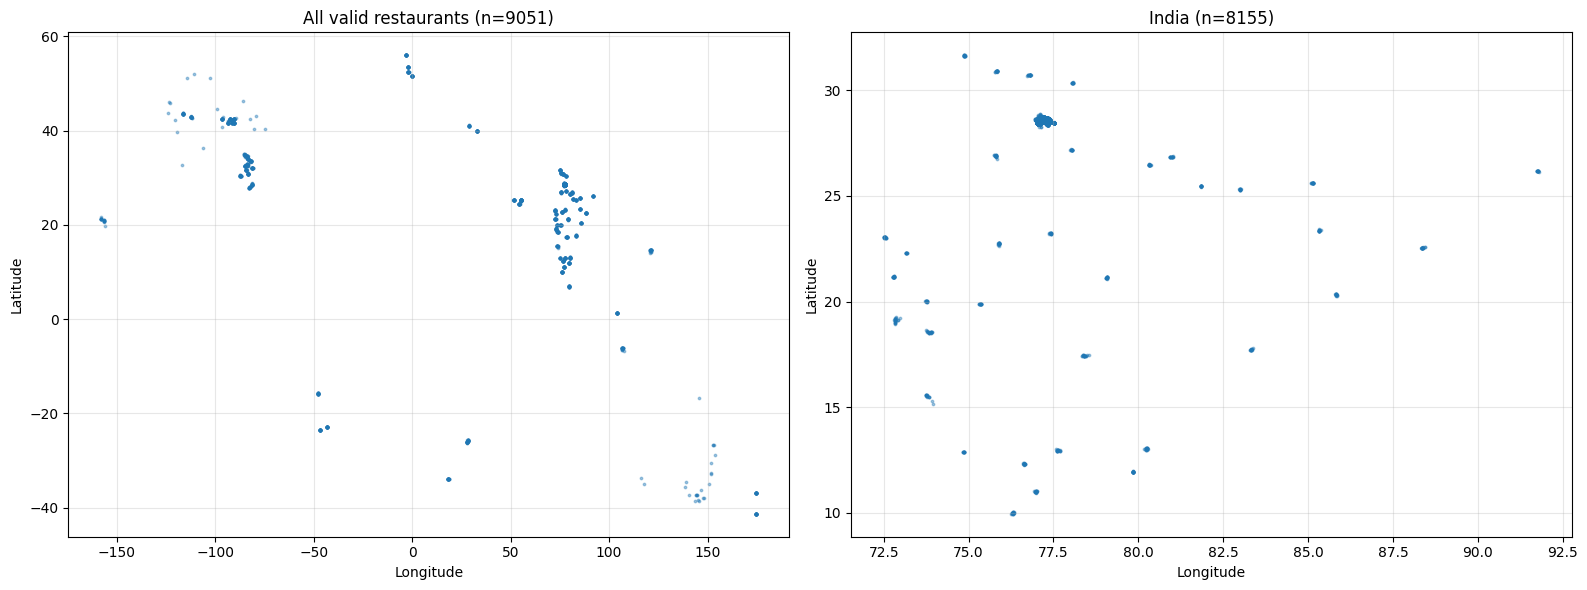

Country code 37: cities (top 8 by count)
City
Chatham-Kent        1
Consort             1
Vineland Station    1
Yorkton             1

Country code 216: cities (top 8 by count)
City
Albany                    20
Athens                    20
Augusta                   20
Boise                     20
Cedar Rapids/Iowa City    20
Dalton                    20
Columbus                  20
Davenport                 20



In [4]:
import matplotlib.pyplot as plt

v = df[df['coord_valid']].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Global view
axes[0].scatter(v['Longitude'], v['Latitude'], s=3, alpha=0.4)
axes[0].set_title(f"All valid restaurants (n={len(v)})")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].grid(alpha=0.3)

# India view (country code 1)
ind = v[v['Country Code'] == 1]
axes[1].scatter(ind['Longitude'], ind['Latitude'], s=3, alpha=0.4)
axes[1].set_title(f"India (n={len(ind)})")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Which cities sit in country codes 37 and 216?
for code in [37, 216]:
    print(f"Country code {code}: cities (top 8 by count)")
    print(v[v['Country Code'] == code]['City'].value_counts().head(8).to_string())
    print()

NCR valid points: 7549
City
New Delhi    5239
Gurgaon      1070
Noida         986
Faridabad     229
Ghaziabad      25


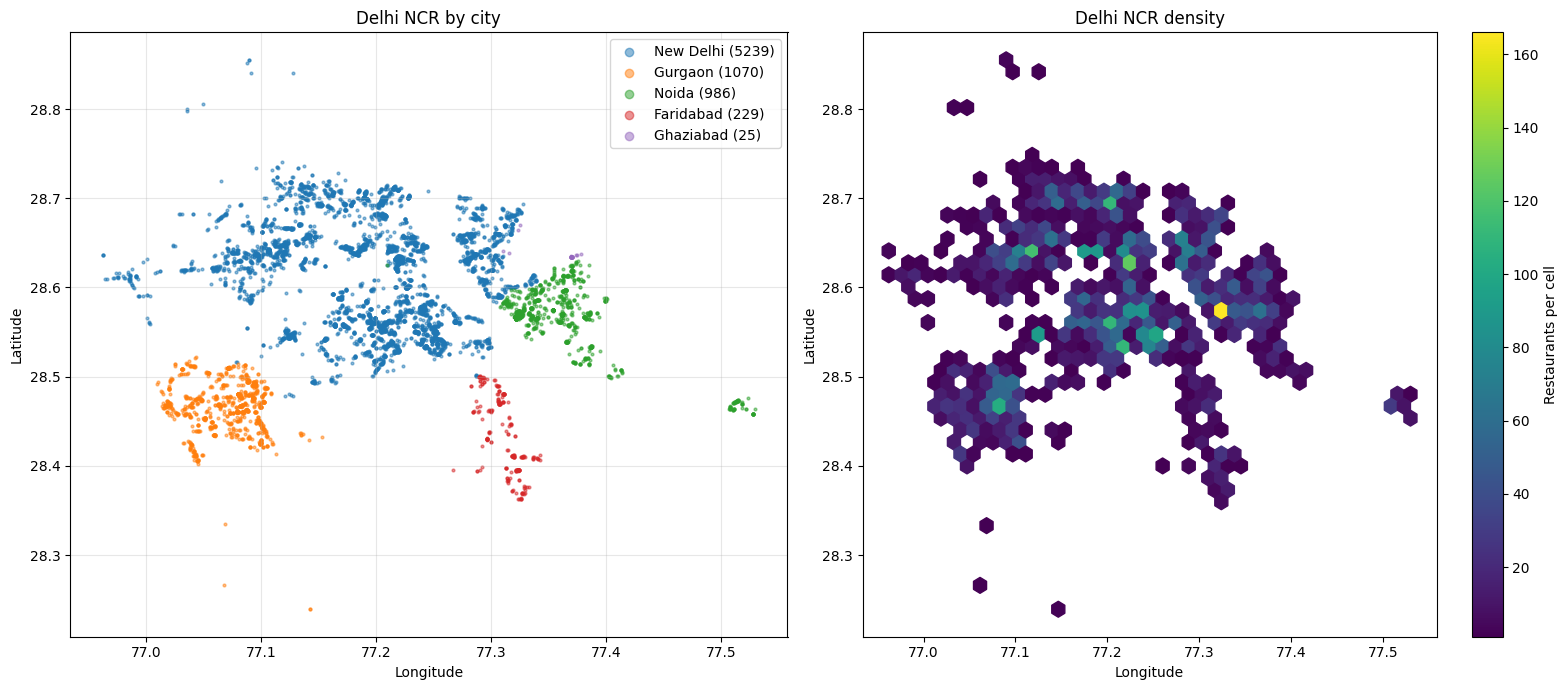

In [5]:
ncr_cities = ['New Delhi', 'Gurgaon', 'Noida', 'Faridabad', 'Ghaziabad']
ncr = v[v['City'].isin(ncr_cities)]
print("NCR valid points:", len(ncr))
print(ncr['City'].value_counts().to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Coloured by city
for c in ncr_cities:
    s = ncr[ncr['City'] == c]
    axes[0].scatter(s['Longitude'], s['Latitude'], s=4, alpha=0.5, label=f"{c} ({len(s)})")
axes[0].set_title("Delhi NCR by city")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
axes[0].legend(markerscale=3); axes[0].grid(alpha=0.3)

# Density (hexbin) to show concentration
hb = axes[1].hexbin(ncr['Longitude'], ncr['Latitude'], gridsize=40, cmap='viridis', mincnt=1)
fig.colorbar(hb, ax=axes[1], label="Restaurants per cell")
axes[1].set_title("Delhi NCR density")
axes[1].set_xlabel("Longitude"); axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

Top non-NCR Indian cities (valid points):
City
Ahmedabad     21
Bangalore     20
Indore        20
Jaipur        20
Coimbatore    20
Chennai       20
Puducherry    20
Pune          20

Zoom: Ahmedabad, 21 points


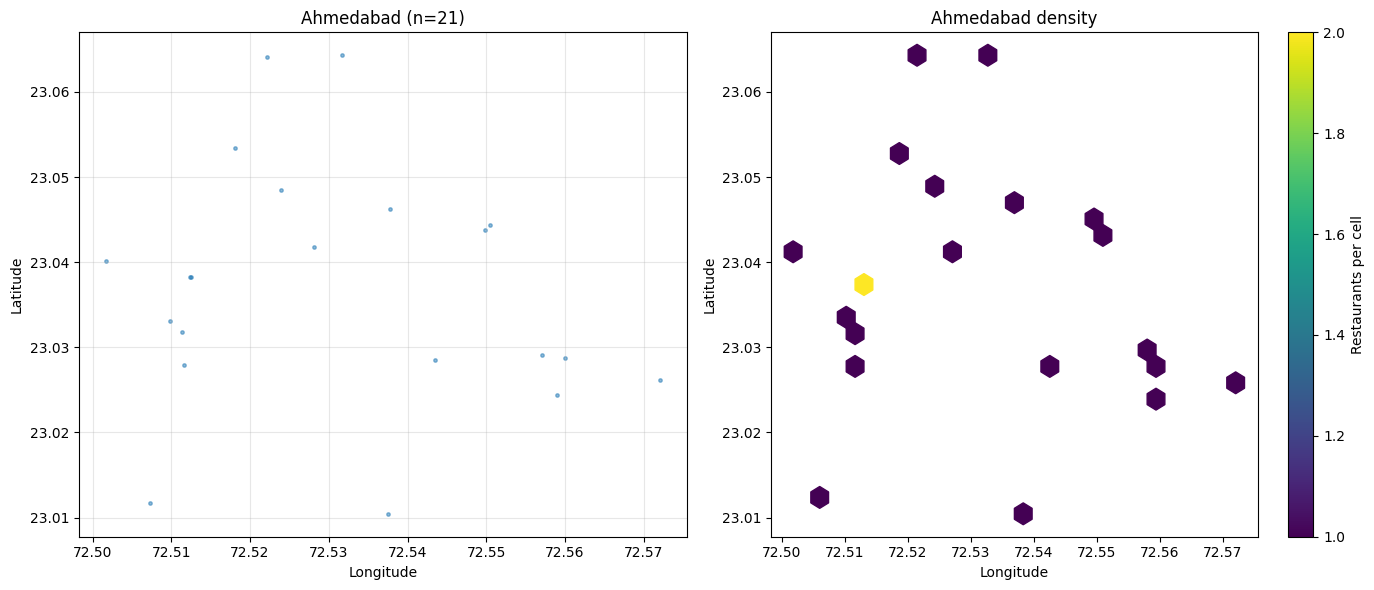

In [6]:
# 1. Top non-NCR Indian cities by valid points
ind = v[v['Country Code'] == 1]
non_ncr = ind[~ind['City'].isin(ncr_cities)]
top_non = non_ncr['City'].value_counts().head(8)
print("Top non-NCR Indian cities (valid points):")
print(top_non.to_string())
print()

# 2. Zoom on the largest one
big = top_non.index[0]
z = non_ncr[non_ncr['City'] == big]
print(f"Zoom: {big}, {len(z)} points")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(z['Longitude'], z['Latitude'], s=6, alpha=0.5)
axes[0].set_title(f"{big} (n={len(z)})")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude"); axes[0].grid(alpha=0.3)
hb = axes[1].hexbin(z['Longitude'], z['Latitude'], gridsize=25, cmap='viridis', mincnt=1)
fig.colorbar(hb, ax=axes[1], label="Restaurants per cell")
axes[1].set_title(f"{big} density")
axes[1].set_xlabel("Longitude"); axes[1].set_ylabel("Latitude")
plt.tight_layout()
plt.show()



In [7]:
import plotly.express as px
pm = ncr[['Restaurant Name', 'City', 'Aggregate rating', 'Latitude', 'Longitude']].copy()

fig = px.scatter(pm, x='Longitude', y='Latitude', color='City',
                 hover_name='Restaurant Name',
                 hover_data={'City': True, 'Aggregate rating': True,
                             'Latitude': ':.3f', 'Longitude': ':.3f'},
                 title=f"Restaurants in Delhi NCR (n={len(pm)}); drag to zoom, hover for details",
                 render_mode='webgl', opacity=0.6)
fig.update_traces(marker=dict(size=4))
fig.update_yaxes(scaleanchor="x", scaleratio=1)
fig.write_html('restaurant_map.html', include_plotlyjs=True)
print("Saved restaurant_map.html with", len(pm), "points")

Saved restaurant_map.html with 7549 points


## Map Visualisation Summary

* **Global and India views:** Scatter plots of the 9051 valid points show clusters in the expected places: India (8155 valid points, densest in Delhi NCR), the USA, the UK, Australia, New Zealand, Brazil, South Africa, Turkey, the Gulf, Singapore and Indonesia. After removing zero coordinates, no points fall in the ocean.
* **Delhi NCR:** It holds 7549 valid points: New Delhi (5239), Gurgaon (1070), Noida (986), Faridabad (229) and Ghaziabad (25). Gurgaon forms a compact south-west cluster, Faridabad a south-east strip, and Noida lies to the east. The brightest density cell (about 165 restaurants) is near longitude 77.32, latitude 28.57, on the Noida and east Delhi border. Its exact locality is not yet identified.
* **Sampling pattern:** US cities (country code 216) have 20 restaurants each, and every Indian city outside NCR has 20 or 21 valid points. This suggests a fixed sample per city outside NCR, so those counts do not reflect real restaurant density. Country code 37 has only 4 restaurants, one per city, so it is excluded from city comparisons.
* **Interactive map:** `restaurant_map.html` is a self-contained Plotly file of the 7549 NCR points, with hover details and no internet dependency. The free OpenStreetMap and CartoDB tile services blocked access when opened locally, and a Folium map without tiles drew nothing, so no street background is included.
* **Single-city zoom outside NCR:** Ahmedabad (21 points) was uninformative and sits about 500 km from NCR, so it was left out of the interactive map. The NCR views serve as the detailed zoom.

In [8]:
# 1. Restaurants per country code
by_country = df['Country Code'].value_counts()
print("Restaurants per country code:")
print(pd.DataFrame({'restaurants': by_country,
                    'share_%': (by_country / len(df) * 100).round(1)}).to_string())
print()

# 2. Restaurants per city: top 10 and the share they hold
by_city = df['City'].value_counts()
print("Top 10 cities:")
print(pd.DataFrame({'restaurants': by_city.head(10),
                    'share_%': (by_city.head(10) / len(df) * 100).round(1)}).to_string())
print()
for k in [1, 4, 10]:
    print(f"Top {k} cities hold {by_city.head(k).sum()} restaurants "
          f"({by_city.head(k).sum() / len(df):.1%})")
print()

# 3. How many cities fall in each size band
bands = pd.cut(by_city, bins=[0, 4, 19, 20, 21, 100, 10000],
               labels=['1-4', '5-19', '20', '21', '22-100', '100+'])
print("Cities by size band:")
print(bands.value_counts().sort_index().to_string())
print()

# 4. Concentration measure: Gini coefficient of city sizes (0 = equal, 1 = one city has everything)
x = np.sort(by_city.values)
n = len(x)
gini = (2 * np.sum((np.arange(1, n + 1)) * x) / (n * x.sum())) - (n + 1) / n
print("Gini coefficient across", n, "cities:", round(gini, 3))

# 5. Same measure inside India only
ind_city = df[df['Country Code'] == 1]['City'].value_counts()
print("India: cities", len(ind_city), "| top 4 NCR cities share of India:",
      f"{ind_city.head(4).sum() / ind_city.sum():.1%}")

Restaurants per country code:
              restaurants  share_%
Country Code                      
1                    8652     90.6
216                   434      4.5
215                    80      0.8
30                     60      0.6
189                    60      0.6
214                    60      0.6
148                    40      0.4
208                    34      0.4
14                     24      0.3
162                    22      0.2
94                     21      0.2
166                    20      0.2
184                    20      0.2
191                    20      0.2
37                      4      0.0

Top 10 cities:
              restaurants  share_%
City                              
New Delhi            5473     57.3
Gurgaon              1118     11.7
Noida                1080     11.3
Faridabad             251      2.6
Ghaziabad              25      0.3
Bhubaneshwar           21      0.2
Lucknow                21      0.2
Ahmedabad              21      0.2
Amritsar 

In [9]:
# 1. Locality overview
loc = df.groupby(['City', 'Locality']).size().rename('n').reset_index()
print("Distinct (city, locality) pairs:", len(loc))
print("Distinct locality names alone:", df['Locality'].nunique())
print("Locality names used in more than one city:",
      (loc.groupby('Locality')['City'].nunique() > 1).sum())
print()

# 2. NCR localities: sizes
ncr_all = df[df['City'].isin(ncr_cities)]
nl = ncr_all.groupby(['City', 'Locality']).size().sort_values(ascending=False)
print("NCR localities:", len(nl))
print("Localities with 1 restaurant:", (nl == 1).sum(),
      "| with 20+:", (nl >= 20).sum(), "| with 50+:", (nl >= 50).sum())
print()
print("Top 15 NCR localities:")
print(nl.head(15).to_string())
print()

# 3. Share held by the top localities in NCR
for k in [10, 20, 50]:
    print(f"Top {k} NCR localities hold {nl.head(k).sum()} of {len(ncr_all)} "
          f"({nl.head(k).sum() / len(ncr_all):.1%})")
print()

# 4. Possible spelling duplicates: same locality text after lowercasing and removing spaces/punctuation
import re
norm = ncr_all['Locality'].str.lower().apply(lambda s: re.sub(r'[^a-z0-9]', '', s))
variants = ncr_all.groupby(norm)['Locality'].nunique()
print("Normalised names with more than one spelling:", (variants > 1).sum())
print(ncr_all[norm.isin(variants[variants > 1].index)]['Locality'].value_counts().head(10).to_string())

Distinct (city, locality) pairs: 1265
Distinct locality names alone: 1208
Locality names used in more than one city: 40

NCR localities: 496
Localities with 1 restaurant: 69 | with 20+: 136 | with 50+: 47

Top 15 NCR localities:
City       Locality           
New Delhi  Connaught Place        122
           Rajouri Garden          99
           Shahdara                87
           Defence Colony          86
           Pitampura               85
           Mayur Vihar Phase 1     84
           Malviya Nagar           84
           Rajinder Nagar          81
           Safdarjung              80
           Satyaniketan            79
Noida      Sector 62               76
New Delhi  Karol Bagh              76
           Krishna Nagar           76
Noida      Sector 18               75
New Delhi  Hauz Khas               74

Top 10 NCR localities hold 887 of 7947 (11.2%)
Top 20 NCR localities hold 1610 of 7947 (20.3%)
Top 50 NCR localities hold 3346 of 7947 (42.1%)

Normalised names with mor

In [10]:
# Locality-level table for NCR (rated restaurants only for the rating average)
ncr_all = ncr_all.copy()
ncr_all['rated'] = ncr_all['Aggregate rating'] > 0
g = ncr_all.groupby(['City', 'Locality']).agg(
    restaurants=('Restaurant ID', 'size'),
    unrated_share=('rated', lambda s: round(1 - s.mean(), 2)),
    avg_rating=('Aggregate rating', lambda s: round(s[s > 0].mean(), 2)),
    avg_price_range=('Price range', 'mean'),
    votes_median=('Votes', 'median'))
g['avg_price_range'] = g['avg_price_range'].round(2)
big = g[g['restaurants'] >= 30].sort_values('restaurants', ascending=False)
print("NCR localities with 30+ restaurants:", len(big))
print(big.head(12).to_string())
print()

# Gini across NCR localities and across NCR cities
def gini(a):
    a = np.sort(np.asarray(a, dtype=float)); n = len(a)
    return (2 * np.sum(np.arange(1, n + 1) * a) / (n * a.sum())) - (n + 1) / n
print("Gini across NCR localities:", round(gini(g['restaurants']), 3))

# Highest and lowest average rating among big localities
print()
print("Top 5 by average rating (30+ restaurants):")
print(big.sort_values('avg_rating', ascending=False).head(5)[['restaurants', 'avg_rating', 'unrated_share']].to_string())
print("Bottom 5 by average rating (30+ restaurants):")
print(big.sort_values('avg_rating').head(5)[['restaurants', 'avg_rating', 'unrated_share']].to_string())

NCR localities with 30+ restaurants: 98
                               restaurants  unrated_share  avg_rating  avg_price_range  votes_median
City      Locality                                                                                  
New Delhi Connaught Place              122           0.02        3.78             2.60         761.5
          Rajouri Garden                99           0.01        3.63             2.20         120.0
          Shahdara                      87           0.53        3.00             1.14           3.0
          Defence Colony                86           0.08        3.49             1.93          81.0
          Pitampura                     85           0.09        3.17             1.47          33.0
          Malviya Nagar                 84           0.00        3.42             1.77         109.0
          Mayur Vihar Phase 1           84           0.32        2.99             1.30           9.5
          Rajinder Nagar                81         

## Concentration Summary

* India accounts for 8652 of 9551 restaurants (90.6%), followed by the USA with 434 (4.5%) and the UK with 80 (0.8%). New Delhi alone contains 5473 restaurants (57.3%), while the four NCR cities (New Delhi, Gurgaon, Noida, and Faridabad) together account for 7922 (82.9%).
* A total of 67 cities have exactly 20 restaurants, and 5 have 21, suggesting a fixed sampling size per city. Another 58 cities have only 1 to 4 restaurants. The city-level Gini coefficient of 0.878 therefore likely reflects data collection patterns more than actual restaurant concentration.
* NCR contains 496 localities and 7947 restaurants. Of these, 136 localities have 20 or more restaurants, and 47 have 50 or more. The top 10 localities account for 11.2% of restaurants, the top 20 for 20.3%, and the top 50 for 42.1%. Connaught Place has the highest count (122), followed by Rajouri Garden (99) and Shahdara (87). The NCR locality Gini coefficient is 0.621.
* No duplicate locality names caused by spelling variations were found in NCR after normalisation (other regions were not tested). However, 40 locality names occur in more than one city, so locality-level grouping uses the combined (city, locality) pair.
* Among the 98 NCR localities with 30 or more restaurants, Sector 29 in Gurgaon has the highest average rating (3.89), followed by Cyber Hub (3.86). The lowest average ratings occur in Najafgarh, Palam, and Sainik Farms, where 71% to 98% of restaurants are unrated. These averages are therefore driven by missing ratings rather than necessarily indicating poor quality.

In [11]:
from collections import Counter
def top_cuisines(s, k=3):
    c = Counter(x.strip() for t in s for x in t.split(','))
    return ", ".join(f"{n}" for n, _ in c.most_common(k))

dfc = df.dropna(subset=['Cuisines']).copy()
dfc['rated'] = dfc['Aggregate rating'] > 0
dfc['table'] = (dfc['Has Table booking'] == 'Yes')
dfc['delivery'] = (dfc['Has Online delivery'] == 'Yes')

cs = dfc.groupby('City').agg(
    country=('Country Code', 'first'),
    restaurants=('Restaurant ID', 'size'),
    unrated_share=('rated', lambda s: round(1 - s.mean(), 2)),
    avg_rating=('Aggregate rating', lambda s: round(s[s > 0].mean(), 2)),
    avg_price_range=('Price range', lambda s: round(s.mean(), 2)),
    table_share=('table', lambda s: round(s.mean(), 2)),
    delivery_share=('delivery', lambda s: round(s.mean(), 2)),
    top_cuisines=('Cuisines', top_cuisines))

city_stats = cs[cs['restaurants'] >= 20].sort_values('restaurants', ascending=False)
print("Cities with 20+ restaurants:", len(city_stats))
print()
print("NCR cities:")
print(city_stats.loc[[c for c in ncr_cities if c in city_stats.index]].to_string())
print()
others = city_stats[~city_stats.index.isin(ncr_cities)]
print("Other cities (indicative, ~20 each): ", len(others))
print("Highest avg rating:")
print(others.sort_values('avg_rating', ascending=False).head(5)[['country','restaurants','avg_rating','unrated_share','avg_price_range']].to_string())
print("Lowest avg rating:")
print(others.sort_values('avg_rating').head(5)[['country','restaurants','avg_rating','unrated_share','avg_price_range']].to_string())
print()
print("Highest avg price range:")
print(others.sort_values('avg_price_range', ascending=False).head(5)[['country','avg_rating','avg_price_range']].to_string())

Cities with 20+ restaurants: 71

NCR cities:
           country  restaurants  unrated_share  avg_rating  avg_price_range  table_share  delivery_share                      top_cuisines
City                                                                                                                                      
New Delhi        1         5473           0.26        3.30             1.62         0.13            0.27  North Indian, Chinese, Fast Food
Gurgaon          1         1118           0.20        3.33             1.86         0.18            0.38  North Indian, Chinese, Fast Food
Noida            1         1080           0.36        3.16             1.60         0.10            0.34  North Indian, Chinese, Fast Food
Faridabad        1          251           0.40        3.10             1.45         0.06            0.14  North Indian, Chinese, Fast Food
Ghaziabad        1           25           0.08        3.10             1.80         0.12            0.40  North Indian, F

In [12]:
# 1. Price-range mix (share of restaurants per tier) for NCR cities
pm_mix = (dfc[dfc['City'].isin(ncr_cities)]
          .groupby('City')['Price range'].value_counts(normalize=True)
          .unstack().round(2))
print("Price-range mix, NCR cities (share per tier):")
print(pm_mix.loc[[c for c in ncr_cities if c in pm_mix.index]].to_string())
print()

# 2. Cuisine profile: top 8 cuisines per big NCR city, as a share of its restaurants
big4 = ['New Delhi', 'Gurgaon', 'Noida', 'Faridabad']
prof = {}
for c in big4:
    sub = dfc[dfc['City'] == c]
    cnt = Counter(x.strip() for t in sub['Cuisines'] for x in t.split(','))
    prof[c] = {k: round(n / len(sub), 2) for k, n in cnt.most_common(8)}
print("Top 8 cuisines per city (share of the city's restaurants):")
print(pd.DataFrame(prof).fillna('-').to_string())
print()

# 3. Cuisine variety: distinct cuisines per city (cities with 20+ restaurants)
variety = dfc.groupby('City')['Cuisines'].apply(
    lambda s: len({x.strip() for t in s for x in t.split(',')}))
variety = variety[variety.index.isin(city_stats.index)]
print("Distinct cuisines, NCR cities:")
print(variety.loc[[c for c in ncr_cities if c in variety.index]].to_string())
print("Most varied other cities (about 20 restaurants each):")
print(variety[~variety.index.isin(ncr_cities)].sort_values(ascending=False).head(5).to_string())

Price-range mix, NCR cities (share per tier):
Price range     1     2     3     4
City                               
New Delhi    0.56  0.30  0.10  0.04
Gurgaon      0.41  0.39  0.14  0.06
Noida        0.52  0.37  0.09  0.02
Faridabad    0.60  0.34  0.06   NaN
Ghaziabad    0.36  0.52  0.08  0.04

Top 8 cuisines per city (share of the city's restaurants):
             New Delhi Gurgaon Noida Faridabad
North Indian      0.44    0.45  0.49      0.49
Chinese            0.3    0.29  0.36      0.38
Fast Food         0.24     0.2  0.25      0.27
Mughlai           0.11     0.1  0.14      0.12
Bakery            0.08     0.1  0.09      0.11
South Indian      0.08       -  0.06      0.07
Street Food       0.08       -     -         -
Desserts          0.07       -     -         -
Continental          -    0.09     -         -
Italian              -    0.08  0.06         -
Cafe                 -    0.07  0.06      0.06
Mithai               -       -     -      0.08

Distinct cuisines, NCR cities:

## City Statistics Summary

* A total of 71 cities have 20 or more restaurants, including 5 in NCR and 66 other cities with approximately 20 restaurants each. Average ratings are calculated using rated restaurants only.
* The four major NCR cities share the same top three cuisines: North Indian, Chinese, and Fast Food. Gurgaon has the highest average price range (1.86), delivery share (0.38), and table-booking share (0.18). Faridabad has the lowest delivery share (0.14) and table-booking share (0.06). Unrated restaurant shares range from 0.20 to 0.40.
* **Price mix:** Faridabad is the most affordable, with 60% of restaurants in tier 1 and none in tier 4. New Delhi has 56% in tier 1, while Gurgaon has the most upmarket mix, with 14% in tier 3 and 6% in tier 4.
* **Cuisine differences:** Continental (0.09), Italian (0.08) and Cafe (0.07) appear in Gurgaon's top 8 but not in the other cities' top 8. Mithai (0.08) appears only in Faridabad's top 8. New Delhi is the only city to feature Street Food (0.08) and Desserts (0.07) among its top 8 cuisines.
* **Distinct cuisines:** New Delhi has 81, Gurgaon 71, Noida 49, Faridabad 30, and Ghaziabad 14. These differences largely reflect city size.
* NCR cities have average ratings ranging from 3.10 to 3.33, while the five highest-rated non-NCR cities average 4.37 to 4.53: London, Rio de Janeiro, Tampa Bay, Bangalore, and Dubai. These cities have almost no unrated restaurants. The difference likely reflects the way the dataset was sampled and should not be interpreted as evidence that these cities have better restaurants.
* The lowest non-NCR average ratings are all from Indian cities: Aurangabad (3.38), Allahabad (3.39), Ranchi and Patna (3.45), and Varanasi (3.51). With approximately 20 restaurants per city, these averages are indicative rather than conclusive.
* Price range appears to be assigned within each country's own pricing scale, so cross-country price rankings should be treated as approximate.

In [13]:
dfl = dfc[dfc['City'].isin(ncr_cities)].copy()
dfl['cl'] = dfl['Cuisines'].apply(lambda t: list({x.strip() for x in t.split(',')}))

# City-level cuisine shares
city_share = {}
for c in ['New Delhi', 'Gurgaon', 'Noida', 'Faridabad']:
    sub = dfl[dfl['City'] == c]
    cnt = Counter(x for l in sub['cl'] for x in l)
    city_share[c] = {k: n / len(sub) for k, n in cnt.items()}

rows = []
for (c, loc_), sub in dfl.groupby(['City', 'Locality']):
    if c not in city_share or len(sub) < 30:
        continue
    cnt = Counter(x for l in sub['cl'] for x in l)
    best = None
    for k, n in cnt.items():
        if n >= 5:
            lift = (n / len(sub)) / city_share[c][k]
            if best is None or lift > best[1]:
                best = (k, lift, n)
    if best:
        rows.append({'city': c, 'locality': loc_, 'restaurants': len(sub),
                     'top_specialty': best[0], 'lift': round(best[1], 2),
                     'count': best[2]})

spec = pd.DataFrame(rows).sort_values('lift', ascending=False)
print("Localities analysed:", len(spec))
print(spec.head(15).to_string(index=False))
print()
print("Most common 'top specialty' across localities:")
print(spec['top_specialty'].value_counts().head(8).to_string())

Localities analysed: 98
     city                             locality  restaurants top_specialty  lift  count
New Delhi                          Khan Market           44      European 18.57     10
New Delhi                           Safdarjung           80       Tibetan 15.64      8
    Noida DLF Mall of India, Sector 18,  Noida           31         Asian 12.44      5
New Delhi                      Connaught Place          122 Mediterranean 10.62      9
New Delhi                         Satyaniketan           79       Mexican  8.15      6
New Delhi                 Netaji Subhash Place           48     Beverages  6.49      7
New Delhi                          Kamla Nagar           65     Beverages  6.16      9
New Delhi                       Rajouri Garden           99         Asian  5.88     10
  Gurgaon                            Sector 29           38         Asian  5.60      8
New Delhi                   Vasundhara Enclave           62       Biryani  5.35      6
New Delhi          

In [14]:
# Stricter version: at least 8 restaurants with the cuisine, and show city-wide counts
city_count = {c: Counter(x for l in dfl[dfl['City'] == c]['cl'] for x in l)
              for c in ['New Delhi', 'Gurgaon', 'Noida', 'Faridabad']}
rows = []
for (c, loc_), sub in dfl.groupby(['City', 'Locality']):
    if c not in city_share or len(sub) < 30:
        continue
    cnt = Counter(x for l in sub['cl'] for x in l)
    best = None
    for k, n in cnt.items():
        if n >= 8:
            lift = (n / len(sub)) / city_share[c][k]
            if best is None or lift > best[1]:
                best = (k, lift, n)
    if best:
        rows.append({'city': c, 'locality': loc_, 'restaurants': len(sub),
                     'specialty': best[0], 'lift': round(best[1], 2),
                     'in_locality': best[2], 'in_city': city_count[c][best[0]]})
spec2 = pd.DataFrame(rows).sort_values('lift', ascending=False)
print("Localities with a specialty (8+ restaurants):", len(spec2), "of 98")
print(spec2.head(12).to_string(index=False))

Localities with a specialty (8+ restaurants): 97 of 98
     city                   locality  restaurants     specialty  lift  in_locality  in_city
New Delhi                Khan Market           44      European 18.57           10       67
New Delhi                 Safdarjung           80       Tibetan 15.64            8       35
New Delhi            Connaught Place          122 Mediterranean 10.62            9       38
New Delhi               Satyaniketan           79          Cafe  6.82           32      325
New Delhi                Kamla Nagar           65     Beverages  6.16            9      123
New Delhi             Rajouri Garden           99         Asian  5.88           10       94
  Gurgaon                  Sector 29           38         Asian  5.60            8       42
New Delhi              Chandni Chowk           67        Mithai  5.21           18      282
New Delhi                Vijay Nagar           31       Italian  4.70           10      376
New Delhi              Ma

## Locality Specialties Summary

* For the 98 NCR localities with 30 or more restaurants, each cuisine's share within a locality was compared with its share in the corresponding city to calculate its lift. The analysis first required at least 5 restaurants for a cuisine, followed by a stricter threshold of 8.
* Under the 5-restaurant threshold, the highest lifts came from cuisines that are rare across the city: European in Khan Market (18.57, based on 10 restaurants) and Tibetan in Safdarjung (15.64, based on 8 restaurants). Several other results were based on only 5 or 6 restaurants, making them less reliable.
* With the stricter 8-restaurant threshold, 97 of 98 localities had an identified specialty. Khan Market (European, 10 of 67 restaurants in New Delhi), Safdarjung (Tibetan, 8 of 35), and Connaught Place (Mediterranean, 9 of 38) stood out as clusters of relatively rare cuisines.
* The strongest-supported specialties combine substantial lift with a larger restaurant count: Cafe in Satyaniketan (32 restaurants, lift 6.82), Mithai in Chandni Chowk (18, lift 5.21), and Cafe in Delhi University-GTB Nagar (15, lift 3.89).
* Under the 5-restaurant threshold, Bakery was the most frequent top specialty, appearing in 13 localities, followed by South Indian in 9, and Mughlai, Fast Food, and Desserts in 8 each.
* The stricter threshold changed at least one specialty (Satyaniketan moved from Mexican to Cafe), which indicates that specialties based on small restaurant counts are sensitive to the threshold and should be treated as less robust.

In [15]:
from scipy.stats import spearmanr

d6 = dfc[dfc['City'].isin(ncr_cities)].copy()
d6['rated'] = d6['Aggregate rating'] > 0

L = d6.groupby(['City', 'Locality']).agg(
    n=('Restaurant ID', 'size'),
    avg_price=('Price range', 'mean'),
    unrated_share=('rated', lambda s: 1 - s.mean()),
    avg_rating=('Aggregate rating', lambda s: s[s > 0].mean() if (s > 0).any() else np.nan),
    median_votes=('Votes', 'median'),
    table_share=('table', 'mean'),
    delivery_share=('delivery', 'mean'))
L = L[L['n'] >= 30].dropna(subset=['avg_rating'])
print("Localities used:", len(L))
print()

def rho(a, b):
    r, p = spearmanr(L[a], L[b])
    return f"rho = {r:.2f} (p = {p:.3g})"

print("Spearman correlations across localities:")
print("  avg price vs avg rating     :", rho('avg_price', 'avg_rating'))
print("  avg price vs median votes   :", rho('avg_price', 'median_votes'))
print("  avg price vs unrated share  :", rho('avg_price', 'unrated_share'))
print("  unrated share vs avg rating :", rho('unrated_share', 'avg_rating'))
print("  avg price vs table share    :", rho('avg_price', 'table_share'))
print("  avg price vs delivery share :", rho('avg_price', 'delivery_share'))
print()

# Quartiles by price: how do the cheapest and priciest quarters of localities differ?
L['price_quartile'] = pd.qcut(L['avg_price'], 4, labels=['Q1 cheapest', 'Q2', 'Q3', 'Q4 priciest'])
print(L.groupby('price_quartile', observed=True)[
    ['avg_price', 'avg_rating', 'median_votes', 'unrated_share', 'table_share', 'delivery_share']
].mean().round(2).to_string())

Localities used: 97

Spearman correlations across localities:
  avg price vs avg rating     : rho = 0.64 (p = 1.08e-12)
  avg price vs median votes   : rho = 0.78 (p = 1.85e-21)
  avg price vs unrated share  : rho = -0.72 (p = 1.23e-16)
  unrated share vs avg rating : rho = -0.68 (p = 2.41e-14)
  avg price vs table share    : rho = 0.84 (p = 2.4e-27)
  avg price vs delivery share : rho = 0.61 (p = 2.89e-11)

                avg_price  avg_rating  median_votes  unrated_share  table_share  delivery_share
price_quartile                                                                                 
Q1 cheapest          1.21        3.04          5.39           0.50         0.02            0.14
Q2                   1.39        3.13         12.07           0.31         0.03            0.26
Q3                   1.54        3.23         35.48           0.22         0.09            0.33
Q4 priciest          2.07        3.45        148.85           0.06         0.27            0.43


In [16]:
from scipy.stats import chi2_contingency

big4 = ['New Delhi', 'Gurgaon', 'Noida', 'Faridabad']
sub = dfc[dfc['City'].isin(big4)]

for col, label in [('delivery', 'online delivery'), ('table', 'table booking')]:
    ct = pd.crosstab(sub['City'], sub[col])
    chi2, p, _, _ = chi2_contingency(ct)
    print(f"{label}: chi-square p = {p:.3g}")
    print((ct[True] / ct.sum(axis=1)).round(3).to_string())
    print()

# Rated-only rating by city, with a simple spread measure
r = sub[sub['rated']]
print("Rated restaurants only:")
print(r.groupby('City')['Aggregate rating'].agg(['count', 'mean', 'median', 'std']).round(2).to_string())

# Share of the four cities' restaurants that are in tier 1
print()
print((sub['Price range'] == 1).groupby(sub['City']).mean().round(2).to_string())

online delivery: chi-square p = 1.1e-19
City
Faridabad    0.139
Gurgaon      0.380
New Delhi    0.272
Noida        0.337

table booking: chi-square p = 1.58e-09
City
Faridabad    0.060
Gurgaon      0.182
New Delhi    0.131
Noida        0.104

Rated restaurants only:
           count  mean  median   std
City                                
Faridabad    151  3.10     3.0  0.36
Gurgaon      890  3.33     3.3  0.49
New Delhi   4048  3.30     3.3  0.46
Noida        696  3.16     3.1  0.47

City
Faridabad    0.60
Gurgaon      0.41
New Delhi    0.56
Noida        0.52


## Insights and Patterns Summary

### Supported by the data

* Across 97 NCR localities with 30 or more restaurants and at least one rating, average price range shows positive correlations with average rating (Spearman rho 0.64), median votes (0.78), table-booking share (0.84), and delivery share (0.61). It correlates negatively with the unrated share (-0.72).
* Across price quartiles, average ratings increase from 3.04 in the cheapest quartile to 3.45 in the priciest. Median votes rise from 5.39 to 148.85 and table-booking share from 0.02 to 0.27, while the unrated share drops from 0.50 to 0.06.
* Online delivery (p = 1.1e-19) and table booking (p = 1.58e-09) differ beyond chance (chi-square test) across New Delhi, Gurgaon, Noida, and Faridabad. Delivery shares are highest in Gurgaon (38.0%), followed by Noida (33.7%), New Delhi (27.2%), and Faridabad (13.9%). Table-booking shares are Gurgaon (18.2%), New Delhi (13.1%), Noida (10.4%), and Faridabad (6.0%).
* Faridabad has the largest tier 1 price share (0.60), while Gurgaon has the smallest (0.41).

### Not supported or only indicative

* The data does not establish that cheaper areas have worse restaurants. The unrated share and average rating correlate at -0.68, and half of the restaurants in cheaper areas have no rating.
* Ratings cannot be reliably compared between NCR and other cities because non-NCR cities appear to contain samples of approximately 20 restaurants each, with almost no unrated restaurants.
* Correlations are calculated between locality-level averages and do not establish causation. Neighbouring localities may also be statistically dependent, so p-values should be treated as indicative.
* Rated-only average ratings are Gurgaon (3.33), New Delhi (3.30), Noida (3.16), and Faridabad (3.10). No significance test was conducted for these differences.

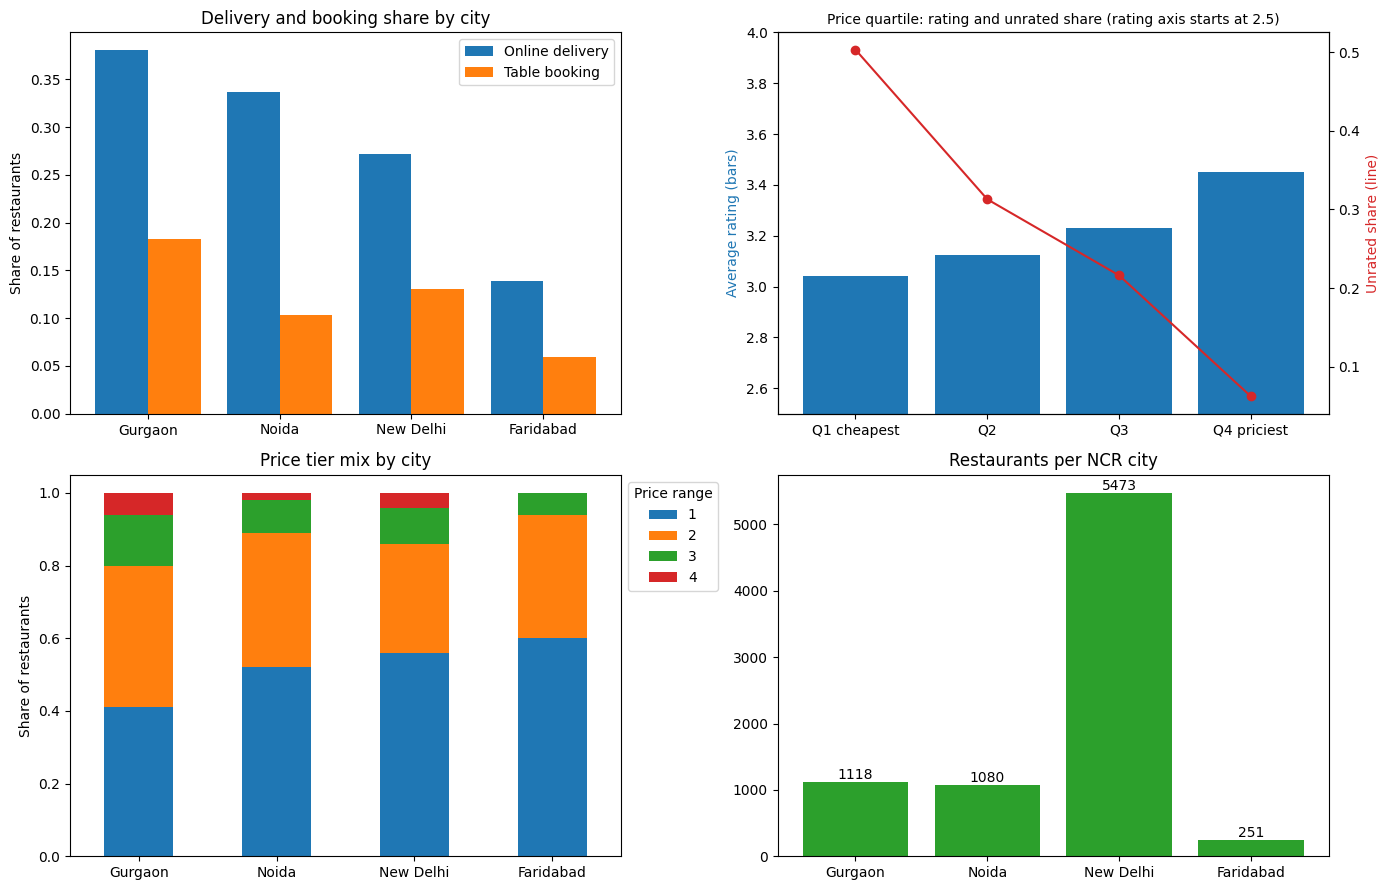

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Delivery and table booking share by NCR city
cities = ['Gurgaon', 'Noida', 'New Delhi', 'Faridabad']
dv = [sub[sub['City'] == c]['delivery'].mean() for c in cities]
tb = [sub[sub['City'] == c]['table'].mean() for c in cities]
x = np.arange(len(cities))
axes[0, 0].bar(x - 0.2, dv, 0.4, label='Online delivery')
axes[0, 0].bar(x + 0.2, tb, 0.4, label='Table booking')
axes[0, 0].set_xticks(x); axes[0, 0].set_xticklabels(cities)
axes[0, 0].set_ylabel("Share of restaurants")
axes[0, 0].set_title("Delivery and booking share by city"); axes[0, 0].legend()

# 2. Price quartile vs average rating and unrated share
q = L.groupby('price_quartile', observed=True)[['avg_rating', 'unrated_share']].mean()
axes[0, 1].bar(q.index.astype(str), q['avg_rating'], color='tab:blue')
axes[0, 1].set_ylim(2.5, 4)
axes[0, 1].set_ylabel("Average rating (bars)", color='tab:blue')
ax2 = axes[0, 1].twinx()
ax2.plot(q.index.astype(str), q['unrated_share'], 'o-', color='tab:red')
ax2.set_ylabel("Unrated share (line)", color='tab:red')
axes[0, 1].set_title("Price quartile: rating and unrated share (rating axis starts at 2.5)", fontsize=10)

# 3. Price tier mix by NCR city
mix = pm_mix.loc[cities].fillna(0)
mix.plot(kind='bar', stacked=True, ax=axes[1, 0])
axes[1, 0].set_title("Price tier mix by city"); axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Share of restaurants")
axes[1, 0].tick_params(axis='x', rotation=0)
axes[1, 0].legend(title="Price range", loc="upper left", bbox_to_anchor=(1.0, 1.0))

# 4. Restaurants per NCR city
cnt = [len(dfc[dfc['City'] == c]) for c in cities]
axes[1, 1].bar(cities, cnt, color='tab:green')
axes[1, 1].bar_label(axes[1, 1].containers[0])
axes[1, 1].set_title("Restaurants per NCR city")

plt.tight_layout()
plt.show()

In [18]:
def summarise_city(name, min_locality=20):
    key = {c.lower(): c for c in dfc['City'].unique()}.get(name.strip().lower())
    if key is None:
        return f"City '{name}' not found."
    s = dfc[dfc['City'] == key]
    out = [f"{key}: {len(s)} restaurants (country code {s['Country Code'].iloc[0]})"]
    if len(s) < 20:
        out.append("Warning: fewer than 20 restaurants, so statistics are unreliable.")
    elif key not in ncr_cities:
        out.append("Note: outside Delhi NCR this looks like a sample of about 20, so counts do not show real density.")
    rated = s[s['rated']]
    out.append(f"Rated restaurants: {len(rated)} (unrated share {1 - s['rated'].mean():.2f})")
    out.append(f"Average rating (rated only): {rated['Aggregate rating'].mean():.2f}" if len(rated) else "No rated restaurants.")
    out.append("Price tier mix: " + ", ".join(f"tier {k}: {v:.0%}" for k, v in
               s['Price range'].value_counts(normalize=True).sort_index().items()))
    out.append(f"Online delivery: {s['delivery'].mean():.0%} | Table booking: {s['table'].mean():.0%}")
    cu = Counter(x.strip() for t in s['Cuisines'] for x in t.split(','))
    out.append("Top cuisines: " + ", ".join(f"{k} ({n})" for k, n in cu.most_common(5)))
    loc = s['Locality'].value_counts()
    big = loc[loc >= min_locality]
    if len(big):
        out.append("Largest localities: " + ", ".join(f"{k} ({n})" for k, n in big.head(5).items()))
    return "\n".join(out)

for c in ['Gurgaon', 'london', 'Miller', 'Atlantis']:
    print(summarise_city(c)); print()

Gurgaon: 1118 restaurants (country code 1)
Rated restaurants: 890 (unrated share 0.20)
Average rating (rated only): 3.33
Price tier mix: tier 1: 41%, tier 2: 39%, tier 3: 14%, tier 4: 6%
Online delivery: 38% | Table booking: 18%
Top cuisines: North Indian (508), Chinese (324), Fast Food (220), Mughlai (117), Bakery (110)
Largest localities: DLF Phase 3 (69), Sector 56 (54), Sector 14 (52), Palam Vihar (49), Sohna Road (42)

London: 20 restaurants (country code 215)
Note: outside Delhi NCR this looks like a sample of about 20, so counts do not show real density.
Rated restaurants: 20 (unrated share 0.00)
Average rating (rated only): 4.53
Price tier mix: tier 2: 30%, tier 3: 40%, tier 4: 30%
Online delivery: 0% | Table booking: 30%
Top cuisines: Indian (5), Curry (4), Japanese (3), American (3), Burger (3)

City 'Miller' not found.

City 'Atlantis' not found.



## Charts and City Profile Function Summary

* Four straightforward charts present the key findings: delivery and table-booking shares across NCR cities, average ratings and unrated shares by locality price quartile, price-tier distribution by city, and restaurant counts by city (New Delhi 5473, Gurgaon 1118, Noida 1080, Faridabad 251). The rating bars begin at 2.5 rather than zero. This is stated in the chart title because the truncated axis makes the differences appear larger.
* `summarise_city(name)` generates a text profile for any city, covering its restaurant count, unrated share, average rating among rated restaurants, price-tier distribution, delivery and booking shares, top five cuisines, and largest localities. It flags cities with fewer than 20 restaurants, notes that non-NCR cities appear to be samples of about 20, and handles unrecognised city names.
* Test results: Gurgaon returned 1118 restaurants, an average rating of 3.33, delivery share of 38%, and table-booking share of 18%. London returned 20 restaurants and an average rating of 4.53, along with the sampling caveat. Miller was not found because its only restaurant had no cuisine listed.
* London's leading cuisines, Indian and Curry, are based on a sample of 20 restaurants. They should not be taken as representative of the city's overall food scene.

In [19]:
script = '''"""
Location-based Analysis: city profile tool
Run: python location_analysis.py
Needs in the same folder: Dataset.csv
"""
from collections import Counter

import pandas as pd

NCR = ['New Delhi', 'Gurgaon', 'Noida', 'Faridabad', 'Ghaziabad']


def fix_city(name):
    if name.isascii():
        return name
    if name.endswith('stanbul'):
        return 'Istanbul'
    if name.startswith('S') and name.endswith('o Paulo'):
        return 'Sao Paulo'
    if name.startswith('Bras') and name.endswith('lia'):
        return 'Brasilia'
    return name


def load():
    df = pd.read_csv('Dataset.csv')
    df['City'] = df['City'].apply(fix_city)
    bad_zero = (df['Latitude'] == 0) | (df['Longitude'] == 0)
    bad_test = (df['Restaurant Name'].str.contains('Test Restaruants', case=False, na=False)
                & (df['City'] == 'New Delhi') & (df['Latitude'] == 35.0))
    df['coord_valid'] = ~(bad_zero | bad_test)
    dfc = df.dropna(subset=['Cuisines']).copy()
    dfc['rated'] = dfc['Aggregate rating'] > 0
    dfc['table'] = dfc['Has Table booking'] == 'Yes'
    dfc['delivery'] = dfc['Has Online delivery'] == 'Yes'
    return df, dfc


def summarise_city(dfc, name, min_locality=20):
    key = {c.lower(): c for c in dfc['City'].unique()}.get(name.strip().lower())
    if key is None:
        return f"City '{name}' not found."
    s = dfc[dfc['City'] == key]
    out = [f"{key}: {len(s)} restaurants (country code {s['Country Code'].iloc[0]})"]
    if len(s) < 20:
        out.append("Warning: fewer than 20 restaurants, so statistics are unreliable.")
    elif key not in NCR:
        out.append("Note: outside Delhi NCR this looks like a sample of about 20, "
                   "so counts do not show real density.")
    rated = s[s['rated']]
    out.append(f"Rated restaurants: {len(rated)} (unrated share {1 - s['rated'].mean():.2f})")
    out.append(f"Average rating (rated only): {rated['Aggregate rating'].mean():.2f}"
               if len(rated) else "No rated restaurants.")
    out.append("Price tier mix: " + ", ".join(
        f"tier {k}: {v:.0%}" for k, v in
        s['Price range'].value_counts(normalize=True).sort_index().items()))
    out.append(f"Online delivery: {s['delivery'].mean():.0%} | Table booking: {s['table'].mean():.0%}")
    cu = Counter(x.strip() for t in s['Cuisines'] for x in t.split(','))
    out.append("Top cuisines: " + ", ".join(f"{k} ({n})" for k, n in cu.most_common(5)))
    loc = s['Locality'].value_counts()
    big = loc[loc >= min_locality]
    if len(big):
        out.append("Largest localities: " + ", ".join(f"{k} ({n})" for k, n in big.head(5).items()))
    return "\\n".join(out)


if __name__ == "__main__":
    df, dfc = load()
    print(f"Loaded {len(df)} restaurants; {int((~df['coord_valid']).sum())} have invalid coordinates "
          f"(excluded from maps only).")
    print("Type a city name (or press Enter to quit).")
    while True:
        city = input("City: ").strip()
        if not city:
            break
        print(summarise_city(dfc, city))
        print()
'''
with open('location_analysis.py', 'w', encoding='utf-8') as f:
    f.write(script)

# Verify in a clean namespace
ns = {}
exec(compile(script.replace('if __name__ == "__main__":', 'if False:'), 'la.py', 'exec'), ns)
d_, c_ = ns['load']()
print("Written:", len(script.splitlines()), "lines")
print("Check:", len(d_), "rows,", int((~d_['coord_valid']).sum()), "invalid coordinates")
print(ns['summarise_city'](c_, 'gurgaon').splitlines()[0])

Written: 77 lines
Check: 9551 rows, 500 invalid coordinates
Gurgaon: 1118 restaurants (country code 1)
